# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Arturo Ygnacio Del Rio Rayas
**Grupo:** 512  **Fecha:** 26/10/2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ruta = "../data/raw/nyc_taxi_examen.csv"

df = pd.read_csv(ruta)

print(df.head(3))
print(df.shape)


   Unnamed: 0  VendorID tpep_pickup_datetime tpep_dropoff_datetime  \
0           0         1  2026-08-01 00:03:04   2026-08-01 00:07:51   
1           1         1  2026-08-01 00:38:45   2026-08-01 00:44:02   
2           2         1                  NaN   2026-08-01 01:01:07   

   passenger_count  trip_distance  RatecodeID  PULocationID  DOLocationID  \
0              1.0            0.6         1.0         140.0         262.0   
1              1.0            0.7         1.0         140.0         262.0   
2            100.0            1.1         1.0         140.0         263.0   

  payment_type  ...  extra  mta_tax  tip_amount  tolls_amount  \
0  Credit card  ...    3.5      0.5        2.30           0.0   
1  Credit card  ...    3.5      0.5        3.45           0.0   
2  Credit card  ...    3.5      0.5        2.60           0.0   

   improvement_surcharge  total_amount  congestion_surcharge  Airport_fee  \
0                    1.0         13.80                   2.5          0.

## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [18]:
df_limpio = df.copy()

print("Nulos por columna originales:")
print(df_limpio.isna().sum())
print("Registros duplicados originales:", df_limpio.duplicated().sum())

df_limpio.drop_duplicates()
df_limpio.dropna()

condiciones = (
    (df_limpio['trip_distance'] > 0) & (df_limpio['passenger_count'] > 0) & 
    (df_limpio['passenger_count'] < 100) & (df_limpio['fare_amount'] > 0) &
    (df_limpio['fare_amount'] < 10000) & (df_limpio['trip_duration'] > 0)
)
df_limpio = df_limpio[condiciones].copy()

print("")
print("Registros restantes en df_limpio:", df_limpio.shape[0])
print("Dimensiones finales:", df_limpio.shape)

Nulos por columna originales:
Unnamed: 0                   0
VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64
Registros duplicados originales: 0

Registros restantes en df_limpio: 2271568
Dimensiones finales: (2271568, 21)


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [19]:
df_cash = df_limpio[df_limpio['payment_type'] == 'Cash'].copy()

X = df_cash[['trip_distance', 'trip_duration']].copy()

print(f"Cantidad de viajes pagados en efectivo: {len(X):,}")
print("Estadísticas descriptivas:")
print(X.describe())

Cantidad de viajes pagados en efectivo: 304,165
Estadísticas descriptivas:
       trip_distance  trip_duration
count  304165.000000  304165.000000
mean        3.843548      17.522115
std         6.150723      40.259946
min         0.010000       0.033333
25%         0.920000       7.400000
50%         1.700000      12.433333
75%         4.370000      20.900000
max      1686.490000    8373.666667


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [25]:
X_log = np.log1p(X)

scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_log)

X_escalado_df = pd.DataFrame(X_escalado, columns=['trip_distance', 'trip_duration'])

print("Estadísticas descriptivas:")
print(X_escalado_df.describe())

Estadísticas descriptivas:
       trip_distance  trip_duration
count   3.041650e+05   3.041650e+05
mean    2.541616e-17  -3.401280e-16
std     1.000002e+00   1.000002e+00
min    -1.592502e+00  -3.458459e+00
25%    -7.510888e-01  -6.445107e-01
50%    -3.045270e-01  -1.401371e-02
75%     5.960928e-01   6.423205e-01
max     8.127937e+00   8.627790e+00


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

Tabla comparativa de métricas:
 k       Inercia  Silueta
 2 245545.895946 0.526478
 3 148333.860914 0.446784
 4 108582.993829 0.413424
 5  85496.530541 0.398179
 6  72296.485504 0.377510


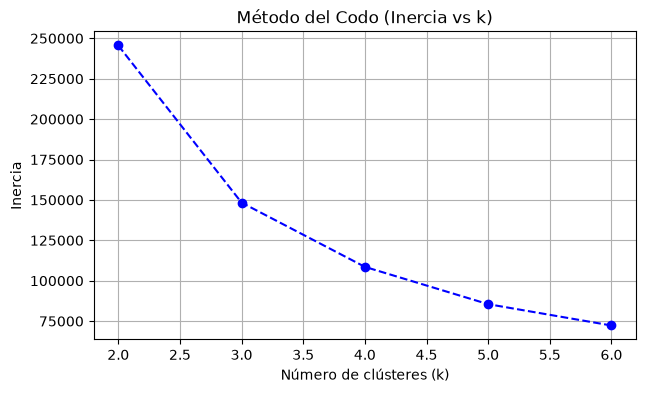

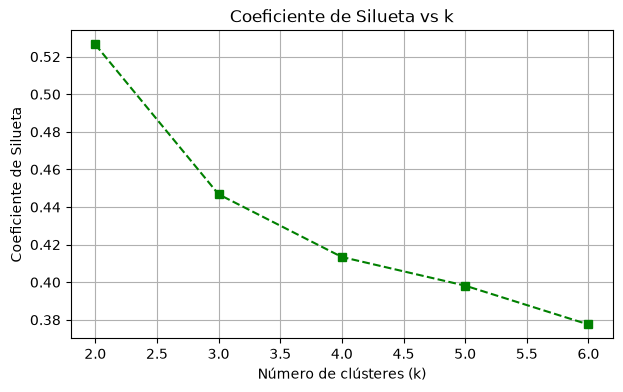

In [26]:
k_valores = list(range(2, 7))
inercias = []
siluetas = []

for k in k_valores:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_escalado)
    
    inercias.append(kmeans.inertia_)
    
    sil_score = silhouette_score(X_escalado, labels, sample_size=5000, random_state=42)
    siluetas.append(sil_score)

df_evaluacion = pd.DataFrame({
    'k': k_valores,
    'Inercia': inercias,
    'Silueta': siluetas
})
print("Tabla comparativa de métricas:")
print(df_evaluacion.to_string(index=False))

plt.figure(figsize=(7, 4))
plt.plot(k_valores, inercias, marker='o', color='b', linestyle='--')
plt.title('Método del Codo (Inercia vs k)')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Inercia')
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(k_valores, siluetas, marker='s', color='g', linestyle='--')
plt.title('Coeficiente de Silueta vs k')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Coeficiente de Silueta')
plt.grid(True)
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

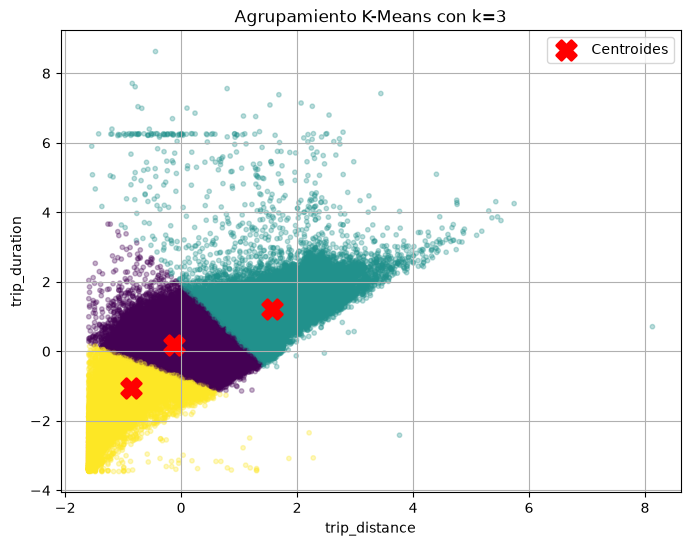

In [28]:
k_optimo = 3
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_escalado)
centroides = kmeans_final.cluster_centers_

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_escalado[:, 0], 
    X_escalado[:, 1], 
    c=cluster_labels, 
    cmap='viridis', 
    alpha=0.3, 
    s=10
)

plt.scatter(
    centroides[:, 0], 
    centroides[:, 1], 
    c='red', 
    marker='X', 
    s=200, 
    linewidths=2, 
    label='Centroides'
)

plt.title(f'Agrupamiento K-Means con k={k_optimo}')
plt.xlabel('trip_distance')
plt.ylabel('trip_duration')
plt.legend()
plt.grid(True)
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:**<br>
Se seleccionó k = 3 porque en el Método del Codo, se observa el punto de inflexión alrededor de en k = 3.<br>

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**<br>
Clúster 0 (Viajes Cortos): Viajan ~1.2 millas y les toma ~6-8 minutos. Parecen traslados a tiendas cercanas.
<br>
Clúster 1 (Viajes Intermedios): Viajan ~3.5 millas y les toma 15 a 25 minutos. Parecen viajes entre colonias o centros comerciales alejados.
<br>
Clúster 2 (Viajes Largos): Viajan mas de 9 millas y les toma mas de 35 minutos. Parecen translados de extremo a extremo de la ciudad.
<br>

**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:** <br>
El Clúster 2 tiene la mayor duración promedio de viaje. Sí coincide directamente con presentar la mayor distancia promedio, refleja una relación positiva entre el tiempo de recorrido y las millas acumuladas en trayectos largos.

<br>
**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

**Respuesta:**<br>
El Clúster 0 es el mas numeroso. Lo comun es viajar menos de 2 millas y con duraciones breves (menos de 10 minutos).

---
### Lista de verificación antes de entregar

- [X] Se muestran la carga, exploración, limpieza y filtrado.
- [X] Se utilizaron las **dos variables indicadas**.
- [X] Se aplicaron `log1p` y `StandardScaler`.
- [X] Se calcularon inercia y silueta para `k = 2...6`.
- [X] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [X] Se visualizan los clústeres y sus centroides.
- [ ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [X] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**